# F1 EDA - Is the race decided on Saturday?

Majed Alotaibi - AI student, University of Hail - Unit 3 Final Project

# Step 1 - Dataset

* **Title:** Formula 1 World Championship (1950-2020) by Rohan Rao
* **Source:** [Kaggle](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020)
* **Description:** every F1 race from 1950 until now, taken from the Ergast API. it has 14 csv files
  (results, races, drivers, teams, status...). the name says 2020 but the data goes up to the end of 2024.
  i only use 5 files + circuits for the dashboard.
* **Why i picked it:** im an F1 fan and the data is split into many tables so i have to merge them and clean them myself

# Step 2 - Problem Definition

* **What is the dataset about?** the result of every driver in every race, where they started, where they finished and why they retired

* **Main question:** is the race decided on Saturday? (how much does the qualifying grid position decide the result)

* **Other questions:**
  1. how strong is the link between grid and finishing position, and is it stronger since 2010?
  2. does one team dominate every era?
  3. did cars become more reliable (less DNFs and less mechanical failures)?

* **What i expect to find:**
  * pole position wins a big part of the races
  * every era has one team that wins way more than the others
  * DNFs went down a lot over the years because cars break less

* for grid vs result i use 2010-2024 only because the cars and rules are closer to each other. for reliability and teams i use all years 1950-2024

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('dark_background')
red = '#FF2B17'

# Step 3 - Data Loading & Structure

* load results.csv
* head, shape, info, describe, missing values

In [2]:
results_raw=pd.read_csv('../data/raw/results.csv')
results_raw.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [3]:
results_raw.shape
# 26759 rows
# 18 columns

(26759, 18)

In [4]:
results_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  object 
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  object 
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  object 
 12  milliseconds     26759 non-null  object 
 13  fastestLap       26759 non-null  object 
 14  rank             26759 non-null  object 
 15  fastestLapTime   26759 non-null  object 
 16  fastestLapSpeed  26759 non-null  object 
 17  statusId    

In [5]:
results_raw.describe()

,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId
count,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000
mean,13380.977391,551.687283,278.673530,50.180537,11.134796,12.794051,1.987632,46.301768,17.224971
std,7726.134642,313.265036,282.703039,61.551498,7.202860,7.665951,4.351209,29.496557,26.026104
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
25%,6690.500000,300.000000,57.000000,6.000000,5.000000,6.000000,0.000000,23.000000,1.000000
50%,13380.000000,531.000000,172.000000,25.000000,11.000000,12.000000,0.000000,53.000000,10.000000
75%,20069.500000,811.000000,399.500000,63.000000,17.000000,18.000000,2.000000,66.000000,14.000000
max,26764.000000,1144.000000,862.000000,215.000000,34.000000,39.000000,50.000000,200.000000,141.000000


In [6]:
results_raw.isnull().sum()
# it says there are no missing values but position and milliseconds are object not numbers

resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position           0
positionText       0
positionOrder      0
points             0
laps               0
time               0
milliseconds       0
fastestLap         0
rank               0
fastestLapTime     0
fastestLapSpeed    0
statusId           0
dtype: int64

In [7]:
results_raw['position'].value_counts().head()
# the missing values are saved as \N text so pandas doesnt see them as missing

position
\N    10953
3      1135
4      1135
2      1133
5      1131
Name: count, dtype: int64

## Merge the tables

* load the other files and use na_values so \N becomes NaN
* merge everything into one table (one row per driver per race)

In [8]:
results=pd.read_csv('../data/raw/results.csv', na_values=['\\N'])
races=pd.read_csv('../data/raw/races.csv', na_values=['\\N'])
drivers=pd.read_csv('../data/raw/drivers.csv', na_values=['\\N'])
constructors=pd.read_csv('../data/raw/constructors.csv', na_values=['\\N'])
status=pd.read_csv('../data/raw/status.csv', na_values=['\\N'])
circuits=pd.read_csv('../data/raw/circuits.csv', na_values=['\\N'])

print(results.shape, races.shape, drivers.shape, constructors.shape, status.shape, circuits.shape)

(26759, 18) (1125, 18) (861, 9) (212, 5) (139, 2) (77, 9)


In [9]:
races=races[['raceId', 'year', 'round', 'circuitId', 'name', 'date']]
drivers=drivers[['driverId', 'forename', 'surname', 'nationality']]
constructors=constructors[['constructorId', 'name', 'nationality']]
circuits=circuits[['circuitId', 'name', 'country']]

df=results.merge(races, on='raceId', how='left')
df=df.merge(drivers, on='driverId', how='left')
df=df.merge(constructors, on='constructorId', how='left')
df=df.merge(status, on='statusId', how='left')
df=df.merge(circuits, on='circuitId', how='left')
df.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,name_x,date,forename,surname,nationality_x,name_y,nationality_y,status,name,country
0,1,18,1,1,22.0,1,1.0,1,1,10.0,...,Australian Grand Prix,2008-03-16,Lewis,Hamilton,British,McLaren,British,Finished,Albert Park Grand Prix Circuit,Australia
1,2,18,2,2,3.0,5,2.0,2,2,8.0,...,Australian Grand Prix,2008-03-16,Nick,Heidfeld,German,BMW Sauber,German,Finished,Albert Park Grand Prix Circuit,Australia
2,3,18,3,3,7.0,7,3.0,3,3,6.0,...,Australian Grand Prix,2008-03-16,Nico,Rosberg,German,Williams,British,Finished,Albert Park Grand Prix Circuit,Australia
3,4,18,4,4,5.0,11,4.0,4,4,5.0,...,Australian Grand Prix,2008-03-16,Fernando,Alonso,Spanish,Renault,French,Finished,Albert Park Grand Prix Circuit,Australia
4,5,18,5,1,23.0,3,5.0,5,5,4.0,...,Australian Grand Prix,2008-03-16,Heikki,Kovalainen,Finnish,McLaren,British,Finished,Albert Park Grand Prix Circuit,Australia


In [10]:
df.shape
# still 26759 rows so the merge didnt lose or add any rows

(26759, 31)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 31 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26753 non-null  float64
 5   grid             26759 non-null  int64  
 6   position         15806 non-null  float64
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             7680 non-null   object 
 12  milliseconds     7680 non-null   float64
 13  fastestLap       8252 non-null   float64
 14  rank             8510 non-null   float64
 15  fastestLapTime   8252 non-null   object 
 16  fastestLapSpeed  8252 non-null   float64
 17  statusId    

In [12]:
df.describe()

,resultId,raceId,driverId,constructorId,number,grid,position,positionOrder,points,laps,milliseconds,fastestLap,rank,fastestLapSpeed,statusId,year,round,circuitId
count,26759.000000,26759.000000,26759.000000,26759.000000,26753.000000,26759.000000,15806.000000,26759.000000,26759.000000,26759.000000,7.680000e+03,8252.000000,8510.000000,8252.000000,26759.000000,26759.000000,26759.000000,26759.000000
mean,13380.977391,551.687283,278.673530,50.180537,18.153927,11.134796,8.020499,12.794051,1.987632,46.301768,6.185833e+06,42.732913,10.334313,204.116330,17.224971,1991.394372,8.511192,23.820808
std,7726.134642,313.265036,282.703039,61.551498,15.581135,7.202860,4.840796,7.665951,4.351209,29.496557,1.669306e+06,16.603460,6.140957,21.377265,26.026104,19.952885,5.070231,19.112002
min,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,5.260000e+02,1.000000,0.000000,89.540000,1.000000,1950.000000,1.000000,1.000000
25%,6690.500000,300.000000,57.000000,6.000000,7.000000,5.000000,4.000000,6.000000,0.000000,23.000000,5.378454e+06,33.000000,5.000000,193.322500,1.000000,1977.000000,4.000000,9.000000
50%,13380.000000,531.000000,172.000000,25.000000,16.000000,11.000000,8.000000,12.000000,0.000000,53.000000,5.788194e+06,46.000000,10.000000,204.894000,10.000000,1991.000000,8.000000,18.000000
75%,20069.500000,811.000000,399.500000,63.000000,24.000000,17.000000,11.000000,18.000000,2.000000,66.000000,6.402676e+06,54.000000,15.000000,217.324000,14.000000,2009.000000,12.000000,34.000000
max,26764.000000,1144.000000,862.000000,215.000000,208.000000,34.000000,33.000000,39.000000,50.000000,200.000000,1.509054e+07,85.000000,24.000000,257.320000,141.000000,2024.000000,24.000000,80.000000


In [13]:
df.isnull().sum()

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
year                   0
round                  0
circuitId              0
name_x                 0
date                   0
forename               0
surname                0
nationality_x          0
name_y                 0
nationality_y          0
status                 0
name                   0
country                0
dtype: int64

# Step 4 - Data Cleaning

* missing values (\N)
* convert data types
* fastest lap time to seconds
* grid 0
* rename columns
* new columns (finished, starter, dnf, decade, podium, win)
* duplicates
* save to csv

## 1- Missing values before and after na_values

In [14]:
print('before:')
print(results_raw[['position', 'milliseconds', 'fastestLapTime', 'fastestLapSpeed']].isnull().sum())
print('after:')
print(results[['position', 'milliseconds', 'fastestLapTime', 'fastestLapSpeed']].isnull().sum())
# position is missing when the driver was not classified
# milliseconds is only there for drivers who finished
# fastest lap data only starts from 2004 so older races are empty
# i wont drop these rows because the missing values have a reason

before:
position           0
milliseconds       0
fastestLapTime     0
fastestLapSpeed    0
dtype: int64
after:
position           10953
milliseconds       19079
fastestLapTime     18507
fastestLapSpeed    18507
dtype: int64


## 2- Keep 1950-2024 only

In [15]:
print(df['year'].min(), df['year'].max())
df=df[(df['year']>=1950)&(df['year']<=2024)]
df.shape
# the data already ends at 2024 so nothing was removed but i keep it in case the data gets updated

1950 2024


(26759, 31)

## 3- Convert data types

In [16]:
print(results_raw[['position', 'milliseconds', 'fastestLapSpeed']].dtypes)
df['position']=pd.to_numeric(df['position'], errors='coerce')
df['milliseconds']=pd.to_numeric(df['milliseconds'], errors='coerce')
df['fastestLapSpeed']=pd.to_numeric(df['fastestLapSpeed'], errors='coerce')
print(df[['position', 'milliseconds', 'fastestLapSpeed']].dtypes)

position           object
milliseconds       object
fastestLapSpeed    object
dtype: object
position           float64
milliseconds       float64
fastestLapSpeed    float64
dtype: object


## 4- Fastest lap time to seconds

In [17]:
#lap time looks like 1:27.452 so i add 00: in front to use to_timedelta
df['fastest_lap_sec']=pd.to_timedelta('00:' + df['fastestLapTime']).dt.total_seconds()
df[['fastestLapTime', 'fastest_lap_sec']].dropna().head()

,fastestLapTime,fastest_lap_sec
0,1:27.452,87.452
1,1:27.739,87.739
2,1:28.090,88.090
3,1:28.603,88.603
4,1:27.418,87.418


## 5- Grid 0

In [18]:
print((df['grid']==0).sum())
#grid 0 means the driver started from the pit lane or had no grid slot
#i keep the rows but make a new column where 0 is NaN so it doesnt mess up the grid analysis
df['grid_clean']=df['grid'].replace(0, np.nan)
df[['grid', 'grid_clean']].describe()

1638


,grid,grid_clean
count,26759.000000,25121.000000
mean,11.134796,11.860834
std,7.202860,6.830260
min,0.000000,1.000000
25%,5.000000,6.000000
50%,11.000000,12.000000
75%,17.000000,17.000000
max,34.000000,34.000000


## 6- Rename columns

In [19]:
df.columns.tolist()
#after the merge the name columns got name_x and name_y

['resultId',
 'raceId',
 'driverId',
 'constructorId',
 'number',
 'grid',
 'position',
 'positionText',
 'positionOrder',
 'points',
 'laps',
 'time',
 'milliseconds',
 'fastestLap',
 'rank',
 'fastestLapTime',
 'fastestLapSpeed',
 'statusId',
 'year',
 'round',
 'circuitId',
 'name_x',
 'date',
 'forename',
 'surname',
 'nationality_x',
 'name_y',
 'nationality_y',
 'status',
 'name',
 'country',
 'fastest_lap_sec',
 'grid_clean']

In [20]:
df=df.rename(columns={'name_x': 'race_name', 'name_y': 'team', 'name': 'circuit_name',
                      'nationality_x': 'driver_nationality', 'nationality_y': 'team_nationality'})
df['driver']=df['forename'] + ' ' + df['surname']
df[['race_name', 'circuit_name', 'team', 'driver']].head()

,race_name,circuit_name,team,driver
0,Australian Grand Prix,Albert Park Grand Prix Circuit,McLaren,Lewis Hamilton
1,Australian Grand Prix,Albert Park Grand Prix Circuit,BMW Sauber,Nick Heidfeld
2,Australian Grand Prix,Albert Park Grand Prix Circuit,Williams,Nico Rosberg
3,Australian Grand Prix,Albert Park Grand Prix Circuit,Renault,Fernando Alonso
4,Australian Grand Prix,Albert Park Grand Prix Circuit,McLaren,Heikki Kovalainen


## 7- New columns

* finished: status is Finished or +1 Lap, +2 Laps...
* starter: False if the driver didnt actually start the race
* dnf: started but didnt finish

In [21]:
df['finished']=(df['status']=='Finished') | (df['status'].str.match(r'^\+\d+ Lap'))

not_started=['Did not qualify', 'Did not prequalify', 'Withdrew', 'Did not start', 'Excluded', 'Not classified']
df['starter']=~df['status'].isin(not_started)

df['dnf']=df['starter'] & ~df['finished']
print(df['finished'].sum(), df['starter'].sum(), df['dnf'].sum())

15161 24975 9814


In [22]:
print(df['status'].nunique())
#there are more than 130 status labels so i group the DNFs into 3 types

137


In [23]:
crash=['Accident', 'Collision', 'Collision damage', 'Spun off', 'Fatal accident',
       'Puncture', 'Tyre puncture', 'Damage', 'Debris']
other=['Retired', 'Disqualified', 'Illness', 'Injury', 'Injured', 'Physical', 'Driver unwell',
       'Eye injury', 'Safety concerns', 'Safety', 'Not restarted', '107% Rule', 'Underweight',
       'Out of fuel', 'Tyre', 'Fuel rig', 'Refuelling']

#everything else (engine, gearbox, brakes...) is mechanical
df['dnf_type']='Mechanical'
df.loc[df['status'].isin(crash), 'dnf_type']='Crash/collision'
df.loc[df['status'].isin(other), 'dnf_type']='Other'
df.loc[df['dnf']==False, 'dnf_type']=np.nan
df['dnf_type'].value_counts()

dnf_type
Mechanical         6503
Crash/collision    2819
Other               492
Name: count, dtype: int64

In [24]:
df['decade']=(df['year']//10)*10
df['podium']=df['positionOrder']<=3
df['win']=df['positionOrder']==1
df[['year', 'decade', 'positionOrder', 'podium', 'win']].head()

,year,decade,positionOrder,podium,win
0,2008,2000,1,True,True
1,2008,2000,2,True,False
2,2008,2000,3,True,False
3,2008,2000,4,False,False
4,2008,2000,5,False,False


## 8- Duplicates

In [25]:
print(df.duplicated().sum())
print(df.duplicated(['raceId', 'driverId']).sum())
#no duplicate rows
#91 times the same driver is in the same race twice but thats real, in the 1950s drivers shared cars

0
91


## 9- Save the clean data

In [26]:
df=df[['resultId', 'raceId', 'year', 'round', 'date', 'race_name', 'circuitId', 'circuit_name', 'country',
       'driverId', 'driver', 'driver_nationality', 'constructorId', 'team', 'team_nationality',
       'grid', 'grid_clean', 'position', 'positionOrder', 'points', 'laps', 'milliseconds',
       'fastest_lap_sec', 'fastestLapSpeed', 'status', 'finished', 'starter', 'dnf', 'dnf_type',
       'decade', 'podium', 'win']]
df=df.sort_values(['year', 'round', 'positionOrder'])

df.to_csv('../data/clean_data.csv', index=False)
df.to_csv('../app/clean_data.csv', index=False)
df.shape

(26759, 32)

# Step 5 - EDA

* modern = 2010-2024 (for grid vs result)
* starters = drivers who actually started (for reliability)

In [27]:
modern=df[(df['year']>=2010)&(df['year']<=2024)]
starters=df[df['starter']==True]
wins=df[df['win']==True]
print(modern.shape, modern['raceId'].nunique())

(6436, 32) 305


## Univariate

### 1- Histogram of laps completed

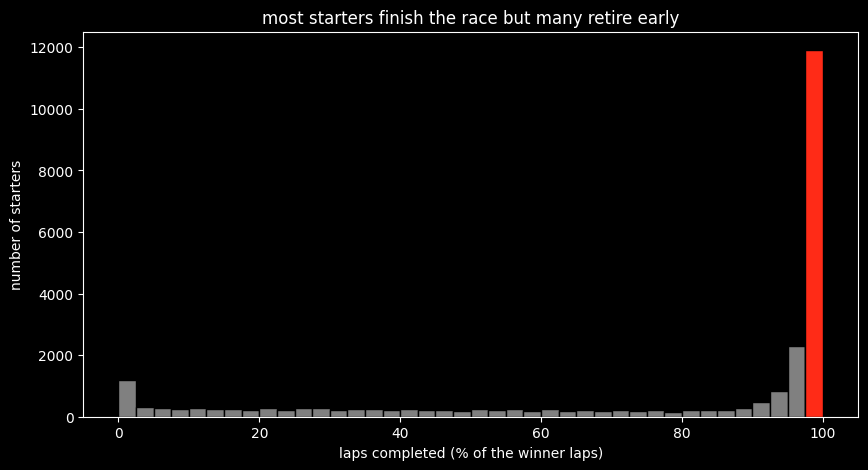

0.47695695695695695


In [28]:
#laps completed as % of the winner laps so short and long races can be compared
max_laps=df.groupby('raceId')['laps'].transform('max')
df['laps_pct']=df['laps']/max_laps*100

plt.figure(figsize=(10,5))
plt.hist(df[df['starter']==True]['laps_pct'], bins=40, color='grey', edgecolor='black')
plt.hist(df[(df['starter']==True)&(df['laps_pct']>=97.5)]['laps_pct'], bins=[97.5, 100], color=red, edgecolor='black')
plt.title('most starters finish the race but many retire early')
plt.xlabel('laps completed (% of the winner laps)')
plt.ylabel('number of starters')
plt.savefig('../reports/figures/01_laps_completed_hist.png', dpi=150, bbox_inches='tight')
plt.show()
print((df[df['starter']==True]['laps_pct']>=97.5).mean())
#about half of the starters reach the end of the race (red bar)
#the bar at 0 is drivers who retired in the first laps

### 2- Countplot of the top 10 teams by wins

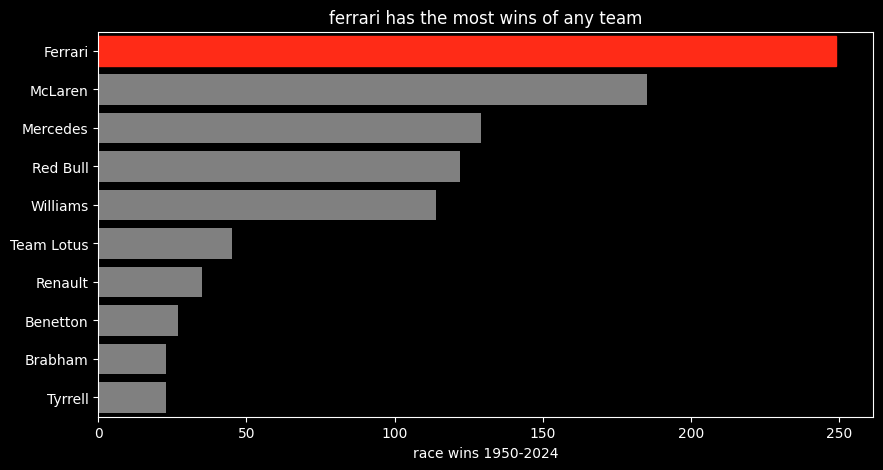

team
Ferrari       249
McLaren       185
Mercedes      129
Red Bull      122
Williams      114
Team Lotus     45
Renault        35
Benetton       27
Brabham        23
Tyrrell        23
Name: count, dtype: int64


In [29]:
top10_teams=wins['team'].value_counts().head(10).index

plt.figure(figsize=(10,5))
sns.countplot(y='team', data=wins[wins['team'].isin(top10_teams)], order=top10_teams, color='grey')
plt.gca().patches[0].set_color(red)
plt.title('ferrari has the most wins of any team')
plt.xlabel('race wins 1950-2024')
plt.ylabel('')
plt.savefig('../reports/figures/02_top_constructors_wins.png', dpi=150, bbox_inches='tight')
plt.show()
print(wins['team'].value_counts().head(10))
#ferrari 249 wins then mclaren 185 and mercedes 129
#mercedes got most of its wins in only 11 seasons

### 3- Countplot of the top 10 DNF reasons (2010-2024)

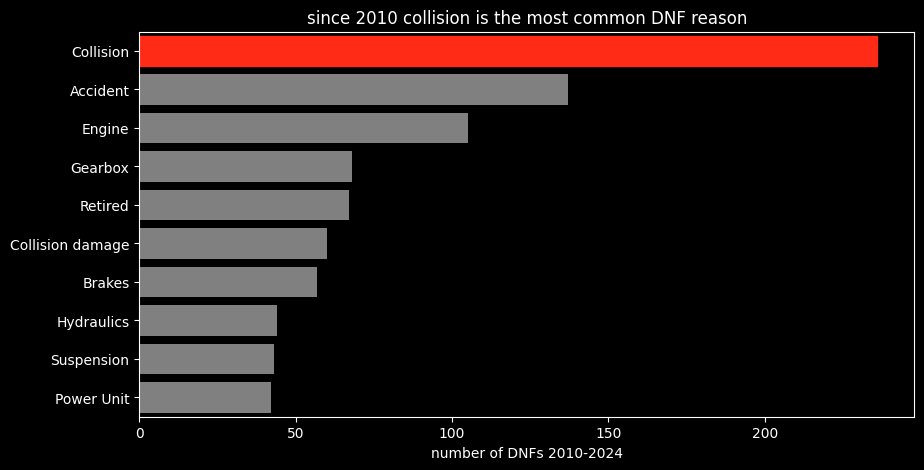

In [30]:
dnf_modern=modern[modern['dnf']==True]
top10_reasons=dnf_modern['status'].value_counts().head(10).index

plt.figure(figsize=(10,5))
sns.countplot(y='status', data=dnf_modern[dnf_modern['status'].isin(top10_reasons)], order=top10_reasons, color='grey')
plt.gca().patches[0].set_color(red)
plt.title('since 2010 collision is the most common DNF reason')
plt.xlabel('number of DNFs 2010-2024')
plt.ylabel('')
plt.savefig('../reports/figures/03_dnf_reasons_modern.png', dpi=150, bbox_inches='tight')
plt.show()
#collision is the biggest single reason
#but mechanical problems are split into many labels (engine, gearbox, brakes..) so together they are still more

### 4- Boxplot of points per race by team (2010-2024)

Index(['Mercedes', 'Red Bull', 'Ferrari', 'McLaren', 'Force India',
       'Williams'],
      dtype='object', name='team')


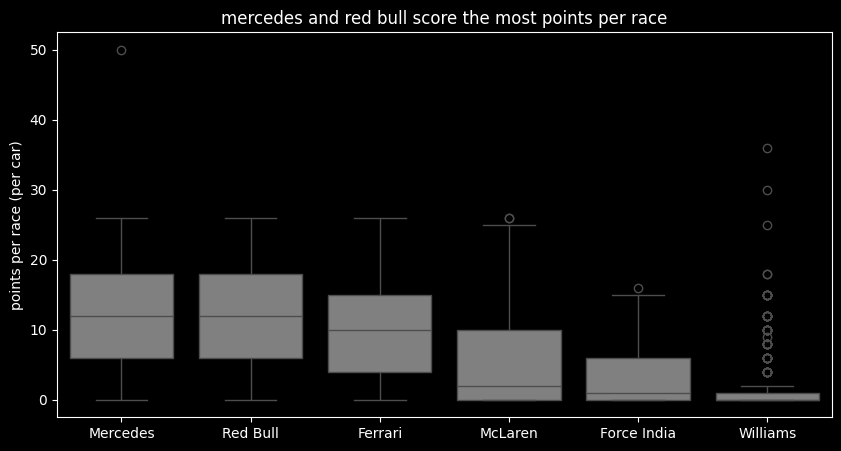

In [31]:
top_teams=modern.groupby('team')['points'].sum().sort_values(ascending=False).head(6).index
print(top_teams)

plt.figure(figsize=(10,5))
sns.boxplot(x='team', y='points', data=modern[(modern['team'].isin(top_teams))&(modern['starter']==True)],
            order=top_teams, color='grey')
plt.title('mercedes and red bull score the most points per race')
plt.xlabel('')
plt.ylabel('points per race (per car)')
plt.savefig('../reports/figures/04_points_by_team_box.png', dpi=150, bbox_inches='tight')
plt.show()
#mercedes and red bull both have a median of 12 points
#force india and williams mostly get 0 or 1
#the outliers at 50 and 36 are abu dhabi 2014 which had double points

## Bivariate & Multivariate

### 5- Scatter plot grid vs finishing position (2010-2024)

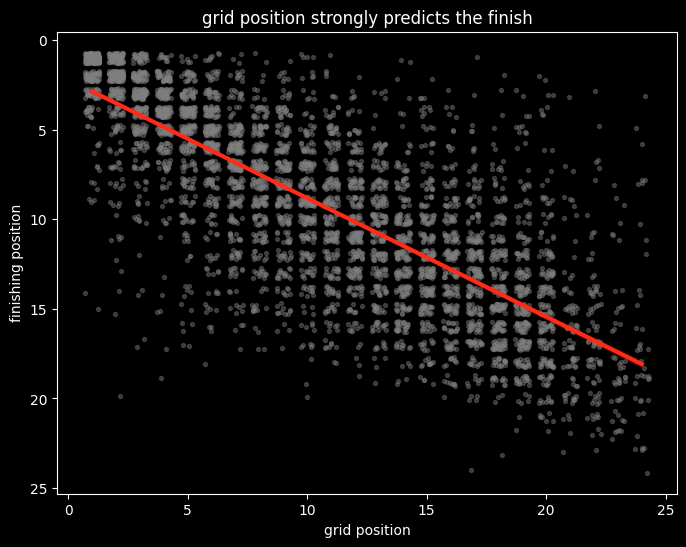

0.7777349534106459


In [32]:
finishers=modern[(modern['finished']==True)&(modern['grid_clean'].notna())]

plt.figure(figsize=(8,6))
sns.regplot(x='grid_clean', y='positionOrder', data=finishers, x_jitter=0.3, y_jitter=0.3,
            scatter_kws={'s': 8, 'alpha': 0.4, 'color': 'grey'}, line_kws={'color': red, 'linewidth': 3})
plt.gca().invert_yaxis()
plt.title('grid position strongly predicts the finish')
plt.xlabel('grid position')
plt.ylabel('finishing position')
plt.savefig('../reports/figures/05_grid_vs_finish_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print(finishers['grid_clean'].corr(finishers['positionOrder']))
#correlation is 0.78 so its a strong positive relationship
#drivers move a few places but if you start at the back you almost never finish at the front

### 6- Bar plot of podium rate by grid slot P1-P10 (2010-2024)

In [33]:
top10_grid=modern[(modern['grid_clean']>=1)&(modern['grid_clean']<=10)]
podium_rate=top10_grid.groupby('grid_clean')['podium'].mean()*100
print(podium_rate.round())

grid_clean
1.0     80.0
2.0     69.0
3.0     51.0
4.0     35.0
5.0     20.0
6.0     14.0
7.0      8.0
8.0      3.0
9.0      4.0
10.0     4.0
Name: podium, dtype: float64


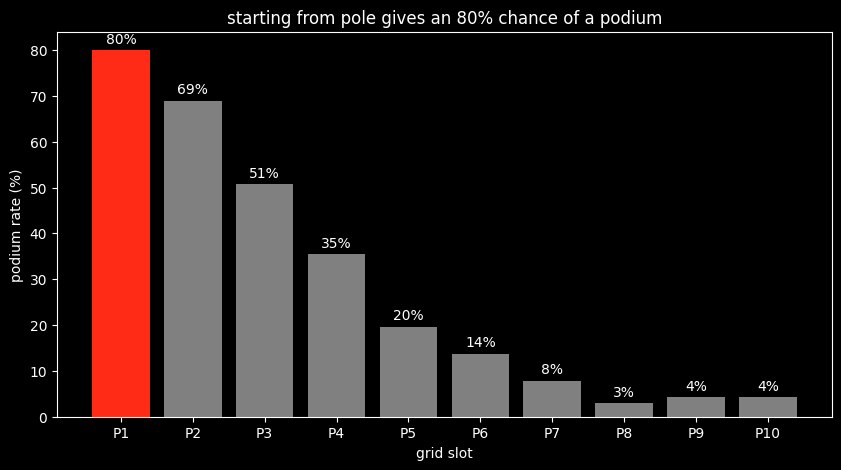

In [34]:
plt.figure(figsize=(10,5))
plt.bar(['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10'], podium_rate, color=[red] + ['grey']*9)
for i in range(10):
    plt.text(i, podium_rate.iloc[i] + 1.5, str(round(podium_rate.iloc[i])) + '%', ha='center')
plt.title('starting from pole gives an 80% chance of a podium')
plt.xlabel('grid slot')
plt.ylabel('podium rate (%)')
plt.savefig('../reports/figures/06_podium_rate_by_grid.png', dpi=150, bbox_inches='tight')
plt.show()
#from P1 its 80% then it drops fast, P5 is only 20%
#from P8 to P10 its almost 0

### 7- Line plot of DNF rate per decade

In [35]:
dnf_rate=starters.groupby('decade')['dnf'].mean()*100
mech_rate=starters.groupby('decade')['dnf_type'].apply(lambda x: (x=='Mechanical').mean())*100
print(dnf_rate.round())
print(mech_rate.round())

decade
1950    49.0
1960    49.0
1970    47.0
1980    55.0
1990    50.0
2000    32.0
2010    19.0
2020    14.0
Name: dnf, dtype: float64
decade
1950    38.0
1960    41.0
1970    32.0
1980    38.0
1990    30.0
2000    19.0
2010    10.0
2020     6.0
Name: dnf_type, dtype: float64


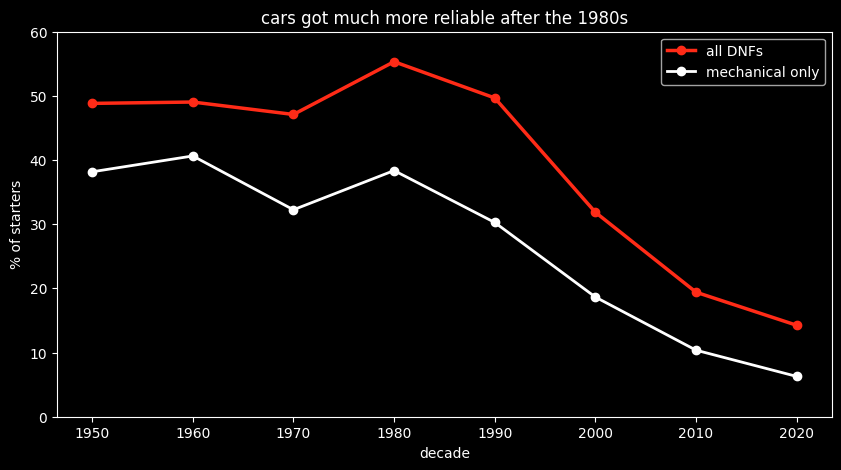

In [36]:
plt.figure(figsize=(10,5))
plt.plot(dnf_rate.index, dnf_rate, marker='o', color=red, linewidth=2.5, label='all DNFs')
plt.plot(mech_rate.index, mech_rate, marker='o', color='white', linewidth=2, label='mechanical only')
plt.title('cars got much more reliable after the 1980s')
plt.xlabel('decade')
plt.ylabel('% of starters')
plt.ylim(0, 60)
plt.legend()
plt.savefig('../reports/figures/07_dnf_rate_by_decade.png', dpi=150, bbox_inches='tight')
plt.show()
#until the 1980s around half of the starters didnt finish
#in the 2020s its only 14%
#mechanical DNFs went from 38% of starters in the 1950s to 6%

### 8- Bar plot of the top team in every era

In [37]:
eras={'1950s': (1950, 1959), '1960s': (1960, 1969), '1970s': (1970, 1979), '1980s': (1980, 1989),
      '1990s': (1990, 1999), '2000s': (2000, 2009), '2010-13': (2010, 2013), '2014-20': (2014, 2020),
      '2021-24': (2021, 2024)}

era_team=[]
era_share=[]
for era in eras:
    start, end=eras[era]
    era_wins=wins[(wins['year']>=start)&(wins['year']<=end)]['team'].value_counts()
    era_team.append(era_wins.index[0])
    era_share.append(era_wins.iloc[0]/era_wins.sum()*100)
    print(era, era_wins.index[0], era_wins.iloc[0], 'of', era_wins.sum(), round(era_wins.iloc[0]/era_wins.sum()*100))

1950s Ferrari 30 of 87 34
1960s Lotus-Climax 22 of 100 22
1970s Ferrari 37 of 144 26
1980s McLaren 56 of 156 36
1990s Williams 61 of 162 38
2000s Ferrari 85 of 174 49
2010-13 Red Bull 41 of 77 53
2014-20 Mercedes 102 of 138 74
2021-24 Red Bull 58 of 90 64


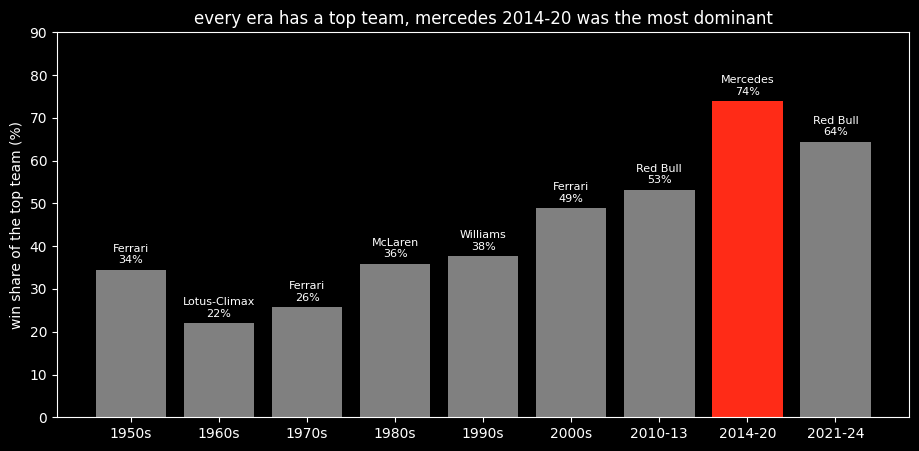

In [38]:
colors=['grey']*9
colors[7]=red

plt.figure(figsize=(11,5))
plt.bar(list(eras.keys()), era_share, color=colors)
for i in range(9):
    plt.text(i, era_share[i] + 1.5, era_team[i] + '\n' + str(round(era_share[i])) + '%', ha='center', fontsize=8)
plt.title('every era has a top team, mercedes 2014-20 was the most dominant')
plt.ylabel('win share of the top team (%)')
plt.ylim(0, 90)
plt.savefig('../reports/figures/08_top_constructor_by_era.png', dpi=150, bbox_inches='tight')
plt.show()
#mercedes won 102 of 138 races from 2014 to 2020 (74%)
#in the 60s and 70s the wins were more spread, since 2000 the top team usually wins half or more

### 9- Correlation heatmap

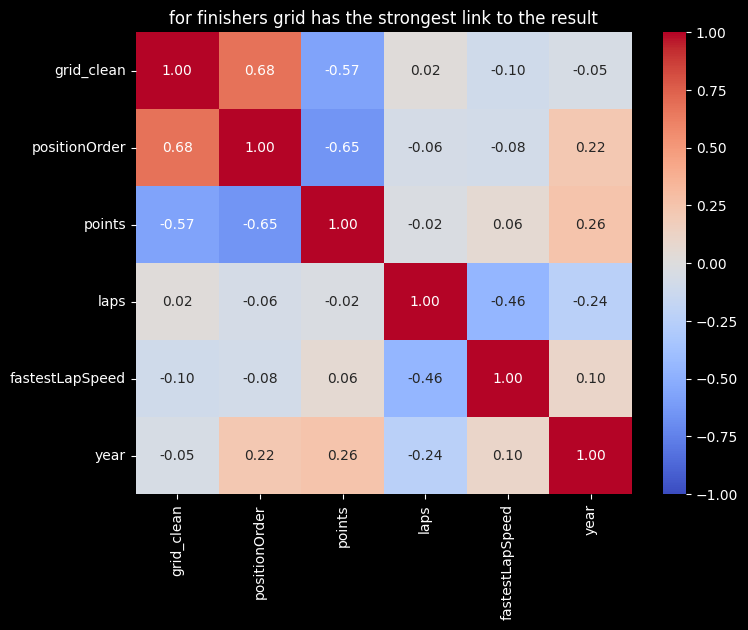

In [39]:
corr=df[df['finished']==True][['grid_clean', 'positionOrder', 'points', 'laps', 'fastestLapSpeed', 'year']].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('for finishers grid has the strongest link to the result')
plt.savefig('../reports/figures/09_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
#grid vs finishing position is 0.68 for all finishers 1950-2024
#points and position are -0.65 but thats expected because points come from the position
#year has almost no link with the result
#fastest lap speed only exists from 2004

### 10- Heatmap grid slot vs finishing position (2010-2024)

In [40]:
grid20=modern[(modern['grid_clean']>=1)&(modern['grid_clean']<=20)&(modern['starter']==True)].copy()
grid20['result']=grid20['positionOrder'].clip(upper=21).astype(str)
grid20.loc[grid20['result']=='21', 'result']='21+'
grid20.loc[grid20['finished']==False, 'result']='DNF'
grid20['grid_clean']=grid20['grid_clean'].astype(int)

order=[str(i) for i in range(1, 21)] + ['21+', 'DNF']
table=pd.crosstab(grid20['grid_clean'], grid20['result'], normalize='index')*100
table=table[order]

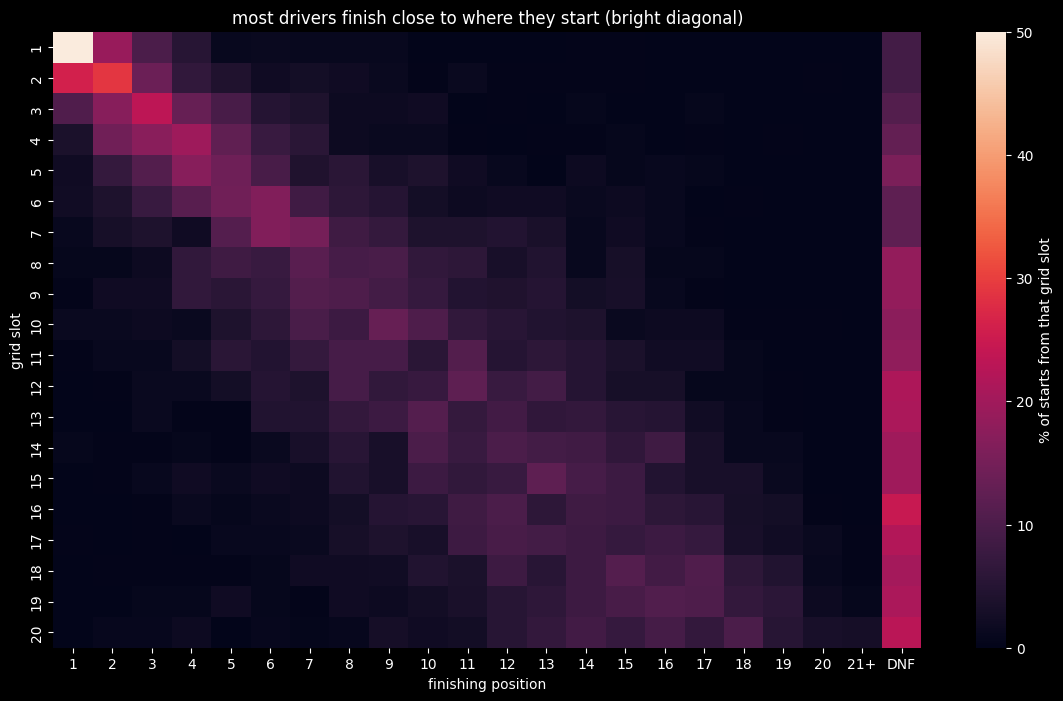

grid_clean
1      9.0
2      9.0
3     11.0
4     13.0
5     16.0
6     12.0
7     12.0
8     19.0
9     18.0
10    18.0
11    18.0
12    21.0
13    21.0
14    20.0
15    20.0
16    24.0
17    22.0
18    20.0
19    21.0
20    23.0
Name: DNF, dtype: float64


In [41]:
plt.figure(figsize=(14,8))
sns.heatmap(table, vmin=0, vmax=50, cbar_kws={'label': '% of starts from that grid slot'})
plt.title('most drivers finish close to where they start (bright diagonal)')
plt.xlabel('finishing position')
plt.ylabel('grid slot')
plt.savefig('../reports/figures/10_grid_finish_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print(table['DNF'].round())
#pole ends in a win 51% of the time
#the DNF column goes from about 9% at the front to about 20% at the back so cars at the back retire twice as much

## Numbers for my presentation

In [42]:
modern_wins=modern[modern['win']==True]

print('rows:', len(df), 'races:', df['raceId'].nunique(), 'drivers:', df['driverId'].nunique(),
      'teams:', df['constructorId'].nunique(), 'seasons:', df['year'].nunique())
print('pole sitter wins:', (modern_wins['grid_clean']==1).mean())
print('front row wins:', (modern_wins['grid_clean']<=2).mean())
print('wins from outside the top 10:', (modern_wins['grid_clean']>10).sum(), 'of', modern['raceId'].nunique())
print('grid vs finish correlation:', finishers['grid_clean'].corr(finishers['positionOrder']))
print('finishers within 3 places:', ((finishers['grid_clean']-finishers['positionOrder']).abs()<=3).mean())

rows: 26759 races: 1125 drivers: 861 teams: 211 seasons: 75
pole sitter wins: 0.5114754098360655
front row wins: 0.7704918032786885
wins from outside the top 10: 4 of 305
grid vs finish correlation: 0.7777349534106459
finishers within 3 places: 0.6667304747320061


In [43]:
print(modern[modern['dnf']==True]['dnf_type'].value_counts(normalize=True)*100)
print(wins[wins['year']==2023]['team'].value_counts().head(1), wins[wins['year']==2023].shape[0])
print(wins['driver'].value_counts().head(3))

dnf_type
Mechanical         50.925110
Crash/collision    41.145374
Other               7.929515
Name: proportion, dtype: float64
team
Red Bull    21
Name: count, dtype: int64 22
driver
Lewis Hamilton        105
Michael Schumacher     91
Max Verstappen         63
Name: count, dtype: int64


In [44]:
#the 4 wins from outside the top 10
modern_wins[modern_wins['grid_clean']>10][['year', 'race_name', 'driver', 'team', 'grid']]

,year,race_name,driver,team,grid
21397,2012,European Grand Prix,Fernando Alonso,Ferrari,11
23977,2018,German Grand Prix,Lewis Hamilton,Mercedes,14
25660,2022,Belgian Grand Prix,Max Verstappen,Red Bull,14
26679,2024,São Paulo Grand Prix,Max Verstappen,Red Bull,17


* most numbers are the same as my presentation
* within 3 places is 67% (the slides say 69%)
* mechanical DNFs in the 1950s is 38% (the slides say 31%) because i count every label that is not a crash or other as mechanical, like Magneto and Axle

# Step 6 - Insights Summary

**Patterns**
* qualifying matters a lot, since 2010 pole won 51% of the races and the front row won 77%
* only 4 of 305 races were won from outside the top 10
* every era has one top team: ferrari in the 2000s, red bull 2010-13, mercedes 2014-20, red bull 2021-24
* cars are way more reliable, about half of the starters retired until the 1980s and now its 14%

**Relationships**
* grid vs finish correlation is 0.78 for finishers since 2010
* 2 out of 3 finishers end within 3 places of where they started
* podium chance drops fast: 80% from P1, 20% from P5, 4% from P8-P10
* since 2010, 51% of retirements are mechanical and 41% are crashes

**Outliers**
* red bull won 21 of 22 races in 2023
* mercedes won 74% of the races from 2014 to 2020
* abu dhabi 2014 gave double points so hamilton got 50 points in one race

**Takeaway:** the race is not 100% decided on saturday but most of it is. the grid and the car decide most of the result and on sunday drivers only move a few places

# Step 7 - Predictive Model (optional)

* predict if a driver gets a podium
* features: grid, team, year (2010-2024)
* teams outside the top 6 become Other
* compare with a baseline model

In [45]:
model_df=modern[(modern['starter']==True)&(modern['grid_clean'].notna())].copy()
model_df['team_group']=model_df['team']
model_df.loc[~model_df['team'].isin(top_teams), 'team_group']='Other'

X=model_df[['grid_clean', 'team_group', 'year']]
y=model_df['podium']
X=pd.get_dummies(X)
print(y.value_counts())
#only 14% are podiums so the classes are not balanced

podium
False    5423
True      915
Name: count, dtype: int64


In [46]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [47]:
#baseline that always says no podium
baseline=DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
y_base=baseline.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_base))
print('Precision:', precision_score(y_test, y_base, zero_division=0))
print('Recall:', recall_score(y_test, y_base))
print('F1:', f1_score(y_test, y_base))
print('ROC-AUC:', roc_auc_score(y_test, baseline.predict_proba(X_test)[:, 1]))

Accuracy: 0.8556782334384858
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.5


In [48]:
model=LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred=model.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1:', f1_score(y_test, y_pred))
print('ROC-AUC:', roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9006309148264984
Precision: 0.708029197080292
Recall: 0.5300546448087432
F1: 0.60625
ROC-AUC: 0.9170305456926293
[[1045   40]
 [  86   97]]


In [49]:
#the baseline gets 86% accuracy but it never finds a podium so accuracy alone is not enough
#the logistic regression is much better, ROC-AUC is about 0.9
#grid does most of the work and the team adds the rest
#the dashboard uses the same model for the predict podium chance part

# Step 8 - Final Summary

**Main insights**
1. grid position is the biggest factor, pole wins about half the races since 2010 and 77% of winners started on the front row
2. one team dominates almost every era and its getting stronger in the modern era
3. cars are way more reliable, DNFs went from about 50% to 14% mostly because less mechanical failures

**What i learned**
* how to merge many tables using IDs and check that the merge didnt lose rows
* missing values are not always NaN, here they were \N and isnull() didnt catch them
* how to group 130+ messy labels into a few groups
* a model needs a baseline because accuracy can look good even when the model does nothing

**Limitations**
* the points system changed many times so i compared positions and wins instead of points
* the status labels are not the same across decades so the mechanical vs crash split is not perfect
* there is no weather, tyre or strategy data
* the grids before the 1980s had different sizes

**Future work**
* add the pit_stops and lap_times tables
* compare street circuits with normal tracks
* improve the podium model with qualifying gaps, driver form and circuit type